In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [5]:
import math
def weighted_avg_and_std(values, weights):
    """
    Return the weighted average and standard deviation.

    values, weights -- Numpy ndarrays with the same shape.
    """
    average = np.average(values, weights=weights)
    # Fast and numerically precise:
    variance = np.average((values-average)**2, weights=weights)
    return (average, math.sqrt(variance))

In [7]:
observables = ['evid','xsec','pt','n','parton','nch','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m','nparents1','nparents2']

In [8]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_50pthat1000_rc_truth.txt']

In [16]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [17]:
df = applyCut(df, 'pt>15')
df.eval('b_ch = q1*q2', inplace=True)

In [18]:
df_pt_array = [ df[(df.pt>15) & (df.pt<20)],\
                       df[(df.pt>20) & (df.pt<25)],\
                       df[(df.pt>25) & (df.pt<30)],\
                       df[(df.pt>30) & (df.pt<40)] ]

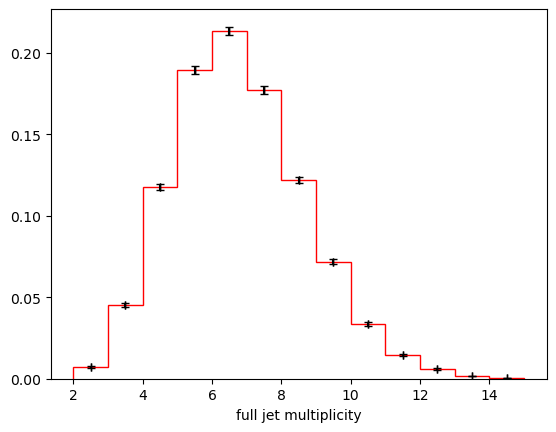

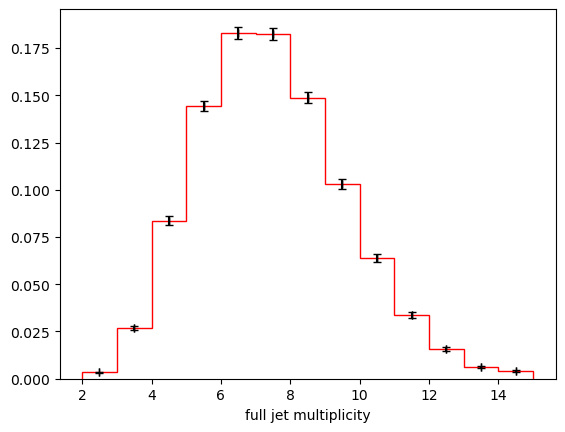

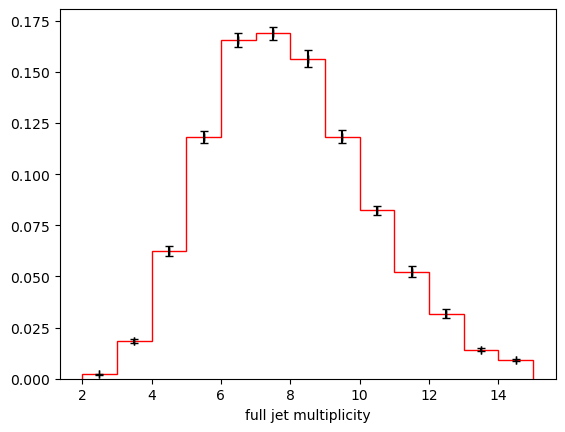

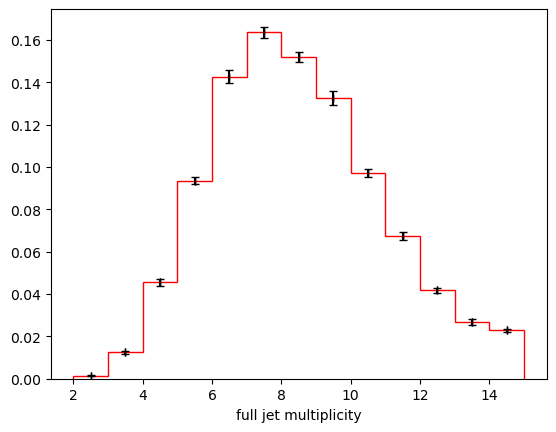

In [21]:
n_array = []
sigma_n_array = []
for i in range(0,4):
    df_temp = df_pt_array[i]
    n, sigma_n = weighted_avg_and_std(df_temp['n'], df_temp['w'])
    n_array.append(n)
    sigma_n_array.append(sigma_n)
    y_temp, yerr_temp, x = calc_hist(df_temp['n'], weights=df_temp['w'], bins=np.arange(2,16), density=True)
    plt.hist(df_temp['n'], weights=df_temp['w'], color='r', histtype='step', bins=np.arange(2,16), density=True)
    plt.errorbar(np.arange(2.5,15.5), y_temp/sum(y_temp), xerr=0, yerr=yerr_temp/sum(y_temp), color='k',ls='none',capsize=3)
    plt.xlabel('full jet multiplicity')
    plt.ylim(bottom=0)
    plt.show()

In [22]:
err_on_mean = []
for j in range(0,4):
    df = df_array[j]
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['n'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean.append(err2)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


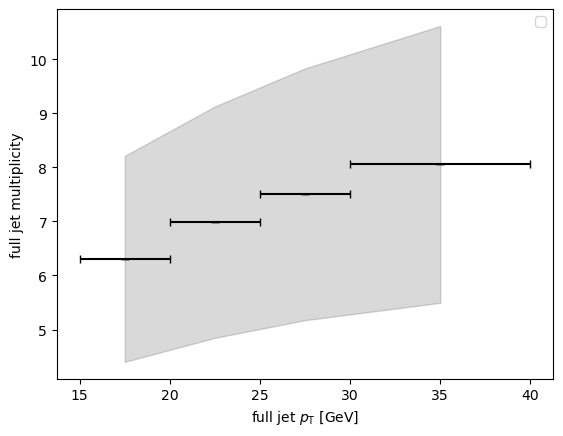

In [25]:
plt.errorbar([17.5, 22.5, 27.5, 35], n_array, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean, color='k',ls='none', capsize=3)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(n_array)-np.array(sigma_n_array), np.array(n_array)+np.array(sigma_n_array), color='k', alpha=0.15)
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]')
plt.ylabel('full jet multiplicity')
#plt.ylim(-0.2,0.2)
plt.legend()